# Markov-Guided Learned State Aggregation

This notebook evaluates two different ways to inject Markov information into learned soft state aggregation. All scripts and the compact result archive used here are kept alongside the notebook under `notebooks/markov_aggregation/`.

The fixed TS/LP/QP/Sketch/ordinary-SA archive is used only as context. The new prototype experiment is a self-training, three-seed paired study with a matched ordinary-SA control.

## 1. Membership Models

Let `g_L(s)` be a finite-horizon Markov signature and let `b(s)` denote the original SA feature immediately before its membership-logit map.

**Ordinary SA** learns logits from its base feature:

$$
W_{s,:}=\operatorname{softmax}(\ell_{\mathrm{base}}(b(s))/\tau).
$$

**Additive Markov SA** keeps this representation and adds a learned Markov correction:

$$
h_\eta(s)=\operatorname{Enc}_\eta(g_L(s),\chi(s)),\qquad
W_{s,:}=\operatorname{softmax}\!\left(
  [\ell_{\mathrm{base}}(b(s))+\alpha\ell_{\mathrm{Markov}}(h_\eta(s))]/\tau
\right).
$$

The historical `e2e`, `detach`, and `scaled` labels differ only in the backward path through `g_L`; they are variants of this *same additive family*.

**Prototype Markov SA** uses the Markov representation itself to define membership:

$$
h_\eta(s)=\big[g_L(s)+\epsilon_h\tanh R_\eta(g_L(s)),\;c\,\chi(s)\big],
$$
$$
q_m=q_m^{(0)}+\epsilon_q\tanh(\delta_m),\qquad
W_{s,m}=\operatorname{softmax}_m\!\left(-\|h_\eta(s)-q_m\|_2^2/\tau\right).
$$

Here `chi(s)` is the normalized inventory/backlog coordinate. Anchoring `q_m` prevents the prototype-collapse failure observed in the first direct-prototype sanity check. The displayed prototype result uses the `detach` backward variant: signatures still determine the forward membership, while their direct derivative is not propagated into the predictor.

## 2. Setup and Data Sources

In [1]:
from pathlib import Path
import json
import math
import os
import subprocess
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from scipy.stats import spearmanr

REPO = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / ".git").exists())
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))
MARKOV_DIR = REPO / "notebooks" / "markov_aggregation"
SCRIPTS = MARKOV_DIR / "scripts"
if str(SCRIPTS) not in sys.path:
    sys.path.insert(0, str(SCRIPTS))

import markov_protocol_runner as base
from markov_prototype_anchored_smoke import AnchoredPrototypeAgg
from mdp_lp.soft_state_aggregation import SoftAggDense
from mdp_lp.inventory_elasticity import create_inventory_from_lambda

warnings.filterwarnings("ignore", message="Sparse invariant checks are implicitly disabled.*")

FIXED_BASELINES = MARKOV_DIR / "results" / "baseline_context.json"
ADDITIVE_ROOT = MARKOV_DIR / "results" / "additive"
INVENTORY_NORMAL_GEOMETRY = ADDITIVE_ROOT / "normal_sa_geometry_inventory_basic.json"
PROTOTYPE_ROOT = MARKOV_DIR / "results" / "prototype"
PROTOTYPE_RUNNER = SCRIPTS / "markov_prototype_anchored_smoke.py"
CACHE_ROOT = REPO / ".cache" / "markov_aggregation"
CLIFF_NORMAL_ROOT = MARKOV_DIR / "results" / "ordinary_controls"
CLIFF_MEASUREMENT_RUNNER = SCRIPTS / "compute_cliff_markov_measurements.py"
CLIFF_MEASUREMENT_PATHS = {
    scale: CLIFF_NORMAL_ROOT / f"cliff_{scale}_measurements.json"
    for scale in ("basic", "medium")
}
PYTHON = Path(sys.executable)

# Re-running this notebook trains only the six small, matched prototype rows
# when they are absent: three ordinary-SA controls and three Markov rows.
RUN_MISSING_PROTOTYPE = True
PROTOTYPE_SEEDS = (0, 1, 2)
M = 30
TAU = 0.02
CHI_SCALE = 30.0

assert FIXED_BASELINES.exists()
assert ADDITIVE_ROOT.exists()
assert CLIFF_NORMAL_ROOT.exists()

In [2]:
def complete_prototype_rows():
    required = [
        PROTOTYPE_ROOT / "inventory" / "basic" / method / f"seed_{seed}" / "record.json"
        for method in ("sa_m30", "markov_detach_m30")
        for seed in PROTOTYPE_SEEDS
    ]
    return all(path.exists() and json.loads(path.read_text(encoding="utf-8")).get("status") == "ok" for path in required)

if RUN_MISSING_PROTOTYPE and not complete_prototype_rows():
    subprocess.run([
        str(PYTHON), str(PROTOTYPE_RUNNER), "--root", str(PROTOTYPE_ROOT), "--data-root", str(CACHE_ROOT),
        "--n-agg", str(M), "--tau", str(TAU), "--state-coordinate-scale", str(CHI_SCALE),
        "--path", "markov_detach", "--seeds", *map(str, PROTOTYPE_SEEDS),
        "--include-ordinary-control",
    ], cwd=REPO, check=True)

baseline_payload = json.loads(FIXED_BASELINES.read_text(encoding="utf-8"))
baseline_records = baseline_payload["records"]
prototype_payload = json.loads((PROTOTYPE_ROOT / "smoke_summary.json").read_text(encoding="utf-8"))
prototype_records = prototype_payload["records"]
additive_payload = json.loads((ADDITIVE_ROOT / "summary.json").read_text(encoding="utf-8"))
additive_records = [
    row for row in additive_payload["records"]
    if row.get("status") == "ok" and not row.get("screen") and row.get("method", "").startswith("markov_")
]

# Cliff basic and medium use separate Python processes because the task keeps
# its grid transition tables as module globals.  This reads saved checkpoints
# only; it does not train a new model.
for cliff_scale, measurement_path in CLIFF_MEASUREMENT_PATHS.items():
    if not measurement_path.exists():
        subprocess.run([
            str(PYTHON), str(CLIFF_MEASUREMENT_RUNNER), "--scale", cliff_scale,
            "--output", str(measurement_path),
        ], cwd=REPO, check=True)

print(f"Fixed baseline rows: {len(baseline_records)}")
print(f"Historical additive-Markov rows: {len(additive_records)}")
print(f"Matched prototype rows: {len(prototype_records)}")

Fixed baseline rows: 90
Historical additive-Markov rows: 150
Matched prototype rows: 6


## 3. Fixed Baseline Context

In [3]:
def result_rows(records, source):
    rows = []
    for row in records:
        result = row.get("result", {})
        if row.get("status") != "ok":
            continue
        rows.append({
            "source": source, "task": row.get("task"), "scale": row.get("scale"),
            "method": row.get("method"), "seed": row.get("seed_index"),
            "M": row.get("n_agg"), "regret": result.get("test_mean_regret"),
            "reward": result.get("test_mean_pred_reward"),
        })
    return pd.DataFrame(rows)

fixed_df = result_rows(baseline_records, "fixed baseline")
context = fixed_df.query("task == 'inventory' and scale == 'basic' and method in ['ts', 'lp', 'qp', 'sketch', 'sa_m30']")
context_summary = context.groupby("method", as_index=False).agg(
    regret_mean=("regret", "mean"), regret_se=("regret", lambda x: x.std(ddof=1) / math.sqrt(len(x))), n=("seed", "count")
)
display(context_summary.round(3))

,method,regret_mean,regret_se,n
0,lp,59.128,5.415,10
1,qp,58.472,4.576,10
2,sa_m30,58.437,6.511,10
3,sketch,58.790,5.507,10
4,ts,60.434,5.294,10


## 4. Paired Decision Effects

,source,task,scale,method,M,paired_regret_delta,delta_se,Markov_regret,ordinary_SA_regret,paired_wins,pairs,seed_deltas,interpretation
0,additive Markov SA,cliff,basic,markov_detach_m12,12,0.106,0.163,7.922,7.816,5,10,"[-0.003, 0.498, -0.002, 0.273, 0.289, 1.027, -...",positive favors ordinary SA
1,additive Markov SA,cliff,basic,markov_e2e_m12,12,0.131,0.166,7.947,7.816,4,10,"[-0.01, 0.082, 0.62, 0.273, 0.343, 1.018, -0.0...",positive favors ordinary SA
2,additive Markov SA,cliff,basic,markov_scaled_m12,12,0.104,0.158,7.920,7.816,4,10,"[-0.002, 0.087, -0.002, 0.273, 0.347, 1.0, -0....",positive favors ordinary SA
3,additive Markov SA,cliff,medium,markov_detach_m12,12,-0.870,1.102,1.024,1.895,6,10,"[-0.972, -1.015, 0.22, -10.062, 2.215, -0.758,...",negative favors Markov
4,additive Markov SA,cliff,medium,markov_e2e_m12,12,-0.430,1.358,1.465,1.895,5,10,"[-1.005, -1.006, 0.188, -10.062, 1.826, -0.969...",negative favors Markov
5,additive Markov SA,cliff,medium,markov_scaled_m12,12,-0.793,1.210,1.102,1.895,7,10,"[-1.015, -1.015, 0.217, -10.057, 1.515, -0.982...",negative favors Markov
6,additive Markov SA,inventory,basic,markov_detach_m10,10,-1.491,2.858,66.241,67.732,5,10,"[-0.256, -0.781, 7.798, 5.032, 0.145, -6.156, ...",negative favors Markov
7,additive Markov SA,inventory,basic,markov_detach_m20,20,-0.617,2.151,62.274,62.890,4,10,"[5.275, -11.888, 0.672, 3.649, 9.535, 0.137, 3...",negative favors Markov
8,additive Markov SA,inventory,basic,markov_detach_m30,30,-1.412,3.023,57.025,58.437,4,10,"[1.837, 6.212, 2.57, 1.873, -6.198, 5.967, -5....",negative favors Markov
9,additive Markov SA,inventory,basic,markov_e2e_m10,10,121.009,22.851,188.741,67.732,0,10,"[174.608, 58.944, 201.962, 176.485, 146.377, 7...",positive favors ordinary SA


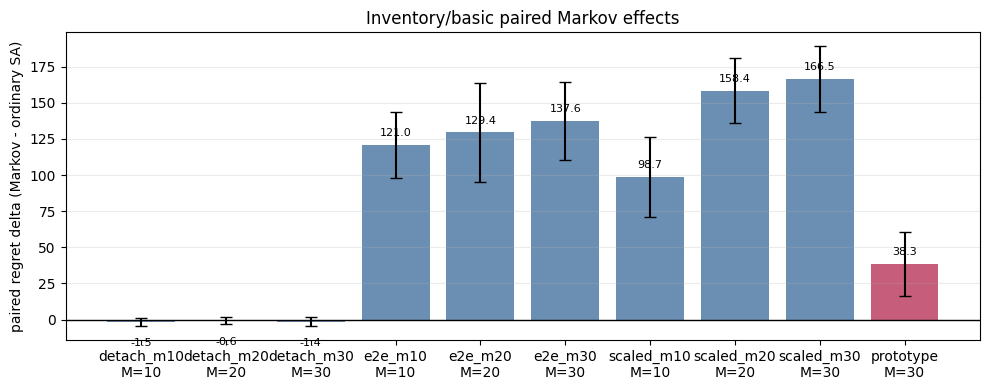

In [4]:
def paired_effect(markov_rows, ordinary_rows, family):
    markov = result_rows(markov_rows, family)
    ordinary = result_rows(ordinary_rows, "ordinary SA")
    ordinary = ordinary.rename(columns={"regret": "ordinary_regret"})[["task", "scale", "method", "seed", "M", "ordinary_regret"]]
    ordinary["method"] = ordinary["method"].str.replace("sa_", "", regex=False)
    markov["ordinary_method"] = markov["M"].map(lambda value: f"m{int(value)}" if pd.notna(value) else None)
    merged = markov.merge(
        ordinary, left_on=["task", "scale", "seed", "ordinary_method"],
        right_on=["task", "scale", "seed", "method"], how="inner", suffixes=("", "_ordinary")
    )
    merged["delta_regret"] = merged["regret"] - merged["ordinary_regret"]
    return merged

historical_controls = [row for row in baseline_records if row.get("method", "").startswith("sa_m")]
additive_pairs = paired_effect(additive_records, historical_controls, "additive Markov SA")
prototype_pairs = paired_effect(
    [row for row in prototype_records if row.get("method") == "markov_detach_m30"],
    [row for row in prototype_records if row.get("method") == "sa_m30"],
    "prototype Markov SA",
)
paired = pd.concat([additive_pairs, prototype_pairs], ignore_index=True)

summary = paired.groupby(["source", "task", "scale", "method", "M"], as_index=False).agg(
    paired_regret_delta=("delta_regret", "mean"),
    delta_se=("delta_regret", lambda x: x.std(ddof=1) / math.sqrt(len(x))),
    Markov_regret=("regret", "mean"), ordinary_SA_regret=("ordinary_regret", "mean"),
    paired_wins=("delta_regret", lambda x: int((x < 0).sum())), pairs=("seed", "count"),
    seed_deltas=("delta_regret", lambda x: [round(float(v), 3) for v in x]),
)
summary["interpretation"] = np.where(summary.paired_regret_delta < 0, "negative favors Markov", "positive favors ordinary SA")
display(summary.round(3))

plot_rows = summary.query("task == 'inventory' and scale == 'basic'").copy()
labels = ["prototype\nM=30" if source == "prototype Markov SA" else method.replace("markov_", "") + f"\nM={int(M)}" for source, method, M in zip(plot_rows.source, plot_rows.method, plot_rows.M)]
fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(labels, plot_rows.paired_regret_delta, yerr=plot_rows.delta_se, capsize=4, color=["#c65d7b" if s == "prototype Markov SA" else "#6b8fb3" for s in plot_rows.source])
ax.axhline(0, color="black", linewidth=1)
ax.set_ylabel("paired regret delta (Markov - ordinary SA)")
ax.set_title("Inventory/basic paired Markov effects")
ax.grid(axis="y", alpha=.25)
for bar, value in zip(bars, plot_rows.paired_regret_delta):
    ax.annotate(f"{value:.1f}", (bar.get_x() + bar.get_width()/2, value), xytext=(0, 5 if value >= 0 else -12), textcoords="offset points", ha="center", va="bottom" if value >= 0 else "top", fontsize=8)
plt.tight_layout()
plt.show()

## 5. Representation and Assignment Measurements

The table is reported separately for Inventory/basic and for Cliff/basic and
Cliff/medium.  Each row uses the matching ordinary-SA and Markov runs with the
same seed; no values are averaged across tasks or scales.

For the matched prototype pair, both trained aggregators are evaluated on the same fresh held-out Inventory MDP. The representation-to-assignment score is

$$
A_{\mathrm{repr}\to W}=\operatorname{Spearman}(D_u(s_i,s_j),D_W(s_i,s_j)),
$$

where each coordinate of `u` is standardized within that MDP and squared pairwise distances are divided by representation dimension.

The cross-method geometry question is instead

$$
A_{\mathrm{SA}\leftrightarrow h}=\operatorname{Spearman}(D_{u_{\mathrm{SA}}},D_h).
$$

This asks whether ordinary SA's learned base representation already organizes states similarly to the Markov representation. Assignment change is label-invariant:

$$
\Delta_C=\operatorname{mean}_{i<j}|(W_\mathrm{Markov}W_\mathrm{Markov}^\top)_{ij}-(W_\mathrm{SA}W_\mathrm{SA}^\top)_{ij}|.
$$

In [5]:
def standardized_distance(representation):
    value = representation.detach().cpu().numpy().astype(float)
    value = (value - value.mean(0, keepdims=True)) / np.maximum(value.std(0, keepdims=True), 1e-8)
    return ((value[:, None, :] - value[None, :, :]) ** 2).mean(-1)

def membership_distance(W):
    return ((W[:, None, :] - W[None, :, :]) ** 2).mean(-1)

def alignment(representation, W):
    upper = np.triu_indices(W.shape[0], k=1)
    return float(spearmanr(standardized_distance(representation)[upper], membership_distance(W)[upper]).statistic)

def entropy(W):
    return float(-(W * np.log(np.maximum(W, 1e-12))).sum(1).mean() / np.log(W.shape[1]))

def inventory_probe(seed, output):
    args = base._inventory_args("sa", base.INVENTORY_RAW_SEEDS[seed], output, "basic", n_agg=M)
    args.sa_tau = TAU
    args.agg_lr_ratio = 0.1
    _, test_loader, _, _ = base._make_inventory_data(args, CACHE_ROOT)
    sample = next(iter(test_loader))
    lam, price = sample[2][:1], sample[3][:1]
    mdp = create_inventory_from_lambda(lam, args.b_max, args.s_max, args.q_max, args.foc, args.voc, args.hc, args.bc, args.beta, price)
    P, r = mdp.P[:1], mdp.r[:1]
    gamma = mdp.build_gamma(1, P.shape[1], torch.device("cpu"))
    return args, P, r, gamma

def cliff_probe(seed, scale, output):
    args = base._cliff_args("sa", base.CLIFF_RAW_SEEDS[seed], output, scale, n_agg=12)
    _, test_loader, _ = base._make_cliff_data(args, base._cliff_setup(scale))
    sample = next(iter(test_loader))
    P, r = sample[3][:1], sample[4][:1]
    gamma = torch.zeros(1, P.shape[1], dtype=P.dtype)
    gamma[:, 0] = 1.0
    return args, P, r, gamma

def load_state(path):
    payload = torch.load(path, map_location="cpu", weights_only=False)
    return payload.get("state_dict", payload)

measurement_rows = []
for seed in PROTOTYPE_SEEDS:
    normal_dir = PROTOTYPE_ROOT / "inventory" / "basic" / "sa_m30" / f"seed_{seed}"
    markov_dir = PROTOTYPE_ROOT / "inventory" / "basic" / "markov_detach_m30" / f"seed_{seed}"
    args, P, r, gamma = inventory_probe(seed, normal_dir)

    normal = SoftAggDense(P.shape[1], P.shape[2], M, r_embed=args.sa_r_embed)
    normal.load_state_dict(load_state(normal_dir / "agg_state_final.pt"))
    with torch.no_grad():
        _, _, _, normal_info = normal(P, r, gamma, tau=TAU)
    base_feature = torch.cat([
        torch.einsum("bsaj,jr->bsar", P, normal.dest_embed.weight).reshape(1, P.shape[1], -1), r
    ], dim=-1)[0]
    W_normal = normal_info["W"][0].detach().cpu().numpy()

    markov_record = json.loads((markov_dir / "record.json").read_text(encoding="utf-8"))
    spec = base.MarkovSpec(**markov_record["spec"])
    markov = AnchoredPrototypeAgg(
        n_states=P.shape[1], n_actions=P.shape[2], n_clusters=M, r_embed=args.sa_r_embed,
        spec=spec, path="markov_detach", state_coordinate_scale=CHI_SCALE,
    )
    markov.load_state_dict(load_state(markov_dir / "aggregation_state.pt"))
    with torch.no_grad():
        _, _, _, markov_info = markov(P, r, gamma, tau=TAU)
        h = markov._representation(P, r)[0]
    W_markov = markov_info["W"][0].detach().cpu().numpy()
    c_delta = np.abs((W_markov @ W_markov.T) - (W_normal @ W_normal.T))[np.triu_indices(P.shape[1], 1)].mean()

    normal_mass, markov_mass = W_normal.sum(0), W_markov.sum(0)
    upper = np.triu_indices(P.shape[1], k=1)
    cross_geometry = float(spearmanr(
        standardized_distance(base_feature)[upper], standardized_distance(h)[upper]
    ).statistic)
    measurement_rows.append({
        "seed": seed,
        "task": "inventory", "scale": "basic", "M": M,
        "implementation": "prototype / detach",
        "ordinary_A_repr_to_W": alignment(base_feature, W_normal),
        "Markov_A_repr_to_W": alignment(h, W_markov),
        "ordinary-Markov representation similarity": cross_geometry,
        "ordinary_entropy": entropy(W_normal), "Markov_entropy": entropy(W_markov),
        "ordinary_MassCV": float(normal_mass.std() / max(normal_mass.mean(), 1e-12)),
        "Markov_MassCV": float(markov_mass.std() / max(markov_mass.mean(), 1e-12)),
        "Delta_C_vs_ordinary": float(c_delta),
    })

measurement_df = pd.DataFrame(measurement_rows)

# Historical additive runs are a separate family.  Reconstruct their actual
# base feature, learned Markov h, and W from saved checkpoints on one shared
# held-out probe per seed; do not substitute raw signature geometry.
normal_geometry_payload = json.loads(INVENTORY_NORMAL_GEOMETRY.read_text(encoding="utf-8"))
normal_checkpoint_by_seed = {
    int(row["seed_index"]): ADDITIVE_ROOT / "ordinary_sa_m30" / f"seed_{int(row['seed_index'])}.pt"
    for row in normal_geometry_payload["records"] if int(row["n_agg"]) == M
}
for route in ("markov_detach_m30", "markov_e2e_m30", "markov_scaled_m30"):
    route_rows = [
        row for row in additive_records
        if row["task"] == "inventory" and row["scale"] == "basic" and row["method"] == route
    ]
    for row in route_rows:
        seed = int(row["seed_index"])
        args, P, r, gamma = inventory_probe(seed, CACHE_ROOT)
        args.sa_tau = float(row.get("protocol_config", {}).get("args", {}).get("sa_tau", 0.5))

        normal = SoftAggDense(P.shape[1], P.shape[2], M, r_embed=args.sa_r_embed)
        normal.load_state_dict(load_state(normal_checkpoint_by_seed[seed]))
        with torch.no_grad():
            _, _, _, normal_info = normal(P, r, gamma, tau=args.sa_tau)
        base_feature = torch.cat([
            torch.einsum("bsaj,jr->bsar", P, normal.dest_embed.weight).reshape(1, P.shape[1], -1), r
        ], dim=-1)[0]
        W_normal = normal_info["W"][0].detach().cpu().numpy()

        spec = base.MarkovSpec(**row["spec"])
        path = route.rsplit("_m", 1)[0]
        markov = base.ProtocolMarkovSoftAgg(
            n_states=P.shape[1], n_actions=P.shape[2], n_clusters=M, r_embed=args.sa_r_embed,
            spec=spec, path=path,
        )
        state = load_state(ADDITIVE_ROOT / "inventory" / "basic" / route / f"seed_{seed}" / "aggregation_state.pt")
        markov.load_state_dict(state)
        with torch.no_grad():
            _, _, _, markov_info = markov(P, r, gamma, tau=args.sa_tau)
            h = markov.signature_encoder(markov._signature(P, r))[0]
        W_markov = markov_info["W"][0].detach().cpu().numpy()
        upper = np.triu_indices(P.shape[1], k=1)
        c_delta = np.abs((W_markov @ W_markov.T) - (W_normal @ W_normal.T))[upper].mean()
        measurement_rows.append({
            "seed": seed,
            "task": "inventory", "scale": "basic", "M": M,
            "implementation": "additive / " + route.removeprefix("markov_").removesuffix("_m30"),
            "ordinary_A_repr_to_W": alignment(base_feature, W_normal),
            "Markov_A_repr_to_W": alignment(torch.cat([base_feature, h], dim=-1), W_markov),
            "ordinary-Markov representation similarity": float(spearmanr(
                standardized_distance(base_feature)[upper], standardized_distance(h)[upper]
            ).statistic),
            "ordinary_entropy": entropy(W_normal), "Markov_entropy": entropy(W_markov),
            "ordinary_MassCV": float(W_normal.sum(0).std() / max(W_normal.sum(0).mean(), 1e-12)),
            "Markov_MassCV": float(W_markov.sum(0).std() / max(W_markov.sum(0).mean(), 1e-12)),
            "Delta_C_vs_ordinary": float(c_delta),
        })

# Cliff/basic and Cliff/medium were measured in separate processes: the task
# keeps its grid dynamics in module-level tables, so one notebook kernel must
# not switch between 48 and 480 states.  These JSON files contain checkpoint
# measurements only, never fallback or invented values.
for measurement_path in CLIFF_MEASUREMENT_PATHS.values():
    measurement_rows.extend(json.loads(measurement_path.read_text(encoding="utf-8")))

measurement_df = pd.DataFrame(measurement_rows)
def mean_se(values):
    values = np.asarray(values, dtype=float)
    return f"{values.mean():.3f} +/- {values.std(ddof=1) / math.sqrt(len(values)):.3f}"

measurement_summary = (measurement_df.groupby(["task", "scale", "M", "implementation"], sort=False)
    .agg(
        **{
            "ordinary-Markov representation similarity": ("ordinary-Markov representation similarity", mean_se),
            "Markov entropy": ("Markov_entropy", mean_se),
            "Delta C vs ordinary": ("Delta_C_vs_ordinary", mean_se),
        }
    )
    .reset_index())

# Attach the paired decision effect from the matching task, scale, aggregation
# size, implementation, and seed set.  Positive values mean Markov had higher
# regret than its ordinary-SA control.
regret_lookup = summary[["source", "task", "scale", "method", "M", "paired_regret_delta", "delta_se"]].copy()
regret_lookup["implementation"] = np.where(
    regret_lookup["source"].eq("prototype Markov SA"),
    "prototype / detach",
    "additive / " + regret_lookup["method"].str.replace("markov_", "", regex=False).str.replace(r"_m\d+$", "", regex=True),
)
regret_lookup["regret delta (Markov - ordinary SA)"] = regret_lookup.apply(
    lambda row: f"{row['paired_regret_delta']:.3f} +/- {row['delta_se']:.3f}", axis=1
)
measurement_summary = measurement_summary.merge(
    regret_lookup[["task", "scale", "M", "implementation", "regret delta (Markov - ordinary SA)"]],
    on=["task", "scale", "M", "implementation"],
    how="left",
)
display(measurement_summary.sort_values(["task", "scale", "M", "implementation"]).reset_index(drop=True))

,task,scale,M,implementation,ordinary-Markov representation similarity,Markov entropy,Delta C vs ordinary,regret delta (Markov - ordinary SA)
0,cliff,basic,12,additive / detach,0.198 +/- 0.052,0.049 +/- 0.007,0.078 +/- 0.006,0.106 +/- 0.163
1,cliff,basic,12,additive / e2e,0.185 +/- 0.044,0.042 +/- 0.007,0.086 +/- 0.008,0.131 +/- 0.166
2,cliff,basic,12,additive / scaled,0.191 +/- 0.040,0.044 +/- 0.009,0.077 +/- 0.007,0.104 +/- 0.158
3,cliff,medium,12,additive / detach,0.369 +/- 0.043,0.166 +/- 0.031,0.095 +/- 0.020,-0.870 +/- 1.102
4,cliff,medium,12,additive / e2e,0.356 +/- 0.030,0.165 +/- 0.025,0.072 +/- 0.012,-0.430 +/- 1.358
5,cliff,medium,12,additive / scaled,0.337 +/- 0.042,0.184 +/- 0.034,0.091 +/- 0.023,-0.793 +/- 1.210
6,inventory,basic,30,additive / detach,0.706 +/- 0.047,0.701 +/- 0.039,0.031 +/- 0.015,-1.412 +/- 3.023
7,inventory,basic,30,additive / e2e,0.680 +/- 0.048,0.795 +/- 0.044,0.063 +/- 0.029,137.616 +/- 26.992
8,inventory,basic,30,additive / scaled,0.680 +/- 0.047,0.811 +/- 0.046,0.071 +/- 0.024,166.460 +/- 22.599
9,inventory,basic,30,prototype / detach,0.918 +/- 0.006,0.282 +/- 0.024,0.344 +/- 0.113,38.252 +/- 22.221
